## Pegasus Evaluation: Tails and Percentiles

Sections B.5 and B.6 of the evaluation of the paper. The evaluation is split into `2a_base_case.ipynb` (A, B.1), `2b_evidence.ipynb` (B.2, B.2b), `2c_depth_and_load.ipynb` (B.3, B.4), `2d_tails_and_percentiles.ipynb` (B.5, B.6) and `2e_iterative.ipynb` (C.1, C.2). `2a_base_case.ipynb` describes
the two data sources, the setup (A) and the metrics and methods (B.1) that every notebook uses; the parameters are
defined once in `pegasus/evaluation_setup.py`. B.5 with real data splits the results of B.1 and computes nothing anew. Choose the data source with `data_source` in the first code cell.

In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
globals().update(configure(data_source))
# the base case of B.1 that this notebook builds on: read from statics/evaluation_cache/ (written by 2a_base_case.ipynb), or
# computed here if the cache is missing or stale (b1_base)
globals().update(b1_base(data_source))
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {n_train} training configurations per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

base case of B.1 loaded from statics\evaluation_cache\b1_real_86637151f18ae038.joblib
real data, 3 seeds: chain detector -> transformer -> compressor, per seed 25 training configurations per service and 99 held-out configurations, poisson arrivals at one rate per configuration (1.58 to 65/s)


## B. Coverage and Tightness of Service Bounds

The metrics, the methods and the rule *validity before tightness* are those of B.1 (`2a_base_case.ipynb`).

### B.5 Varying Tail Behaviors

- **Synthetic:** the execution time of an item gets a lognormal factor whose shape sets how heavy the right tail is
  (`execution_times` in `pegasus/simulation.py`).
- **Real:** a real service has no knob for its tail. The held-out configurations of B.1 are grouped by the tail that
  the testbed measured.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal assume no distribution; the execution-time
  baseline shares the Gaussian assumption.

**Setting (real data).** Nothing is computed anew: the results of B.1 are split into three groups of held-out
configurations of equal size. The *tail ratio* of a run is the 99th percentile ÷ the median of the measured processing
time, for the service of the run at which that ratio is largest; a ratio of 1 would be a processing time without any
scatter. The runs are sorted by their tail ratio and cut into thirds. The horizontal axis of the figure shows the
three groups with the median tail ratio of each. Unlike with synthetic data, the groups also differ in their
configurations, so the tail is not the only thing that changes between them, and a group has a third of the held-out
configurations, so one miss weighs three times as much in its coverage.

**Setting (synthetic data).** For every seed, the chain, the training configurations, the held-out configurations and the Poisson
arrivals of B.1. Only the distribution of the execution time changes. The execution time of an item is its mean
execution time (the same function of the configuration as in B.1) multiplied by a factor $e^{\sigma z - \sigma^2/2}$,
where $z$ is the standard normal draw of the item and $\sigma$ the *tail shape*, one value of `execution_tails` per
setting; the Gaussian noise of B.1 is added as before. The factor is lognormal with mean 1, so the mean execution time
and the utilization of every service are the same in every setting. $\sigma = 0$ is the Gaussian execution time of
B.1. With a larger $\sigma$ most items are faster than the mean and a few are several times slower: the squared
coefficient of variation $C^2$ of the factor, variance ÷ mean², is $e^{\sigma^2} - 1$ and is printed in parentheses after
every tick of the figure. The tail and the variance of the execution time therefore grow together.

Every model is trained anew for every $\sigma$, on data with that tail: one execution time per service and training
configuration for both versions of Pegasus, GP Sum and GP Queue, and each service monitored alone for Quantile Union and
Conformal. No method is told the distribution. Both versions of Pegasus, GP Sum and GP Queue treat an execution time as
Gaussian with the mean and the variance that the model of the service learned; Quantile Union and Conformal learn
latency quantiles and assume no distribution.

**Figure.** The horizontal axis is the tail shape $\sigma$, the vertical axis the tightness, for every seed the median
over its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. In the red area below 1× a method is under the measured quantile and is no bound; the legend sits inside the panel where it hides the fewest points. Every line is the
median over the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker means that
the method holds at that $\sigma$ (it reaches the confidence level under every seed, as defined in B.1), a hollow marker
that it does not. A seed under which a method gives no finite latency at half of the held-out configurations or more
counts as infinitely loose, and the method has no point where that is the case for half of the seeds or more; such a
bound is not violated, but it says nothing. The figure is also saved as `figures/tsc/b5_tails_<data source>.pdf` and `.jpg`.

In [2]:
# B.5: execution times of different tail
if data_source == "synthetic":
    # the chains of B.1 with execution times of different tail shape
    execution_tails = [0, 0.25, 0.5, 0.75, 1.0]   # shape sigma of the lognormal factor of the execution time; 0 is the Gaussian execution time of B.1

    def compute():
        tail_methods, tail_truth = {}, {}   # (tail, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
        with warnings.catch_warnings():
            # with heavy-tailed training data the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for tail in execution_tails:
                for s in seeds:
                    data = chain_data(s, execution_tail=tail)
                    assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
                    assert_unseen(data)
                    models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                    tail_methods[(tail, s)], _ = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                                 model_seed=seed + s, leave_out=only_base_case)
                    tail_truth[(tail, s)] = (data.measured, data.measured_low)
        return dict(tail_methods=tail_methods, tail_truth=tail_truth)

    globals().update(cached("b5_tails", data_source, compute, inputs=dict(execution_tails=execution_tails)))
    factor_cv2 = lambda tail: np.expm1(tail ** 2)   # squared coefficient of variation of the lognormal factor with shape `tail`
    tail_label = lambda tail: f"σ = {tail:g}"
    tail_axis = "tail shape σ of the execution time (C² of its factor)"
    tail_ticks = [f"{tail:g} ({factor_cv2(tail):.2f})" for tail in execution_tails]   # one row: the fixed layout of every figure
else:
    # the held-out configurations of B.1 in three groups of equal size, by the measured tail of their processing times; nothing is
    # computed anew, so nothing is cached
    tail_methods, tail_truth = {}, {}   # (tail, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
    tail_ratio = chain_tail_ratios(base_experiment, unthrottled_runs(base_experiment))               # per held-out run: p99 / median of the processing time, largest over its services
    tail_group = np.digitize(tail_ratio, np.quantile(tail_ratio, [1 / 3, 2 / 3]))   # 0, 1, 2: lightest to heaviest third
    execution_tails = [float(np.median(tail_ratio[tail_group == g])) for g in range(3)]   # a group is named by its median tail ratio
    for g, tail in enumerate(execution_tails):
        for s, (seed_methods, _) in zip(seeds, per_seed):
            tail_methods[(tail, s)] = {name: (group, latency[tail_group == g]) for name, (group, latency) in seed_methods.items() if name not in only_base_case}
            tail_truth[(tail, s)] = (bases[s].measured[tail_group == g], bases[s].measured_low[tail_group == g])
    tail_label = lambda tail: f"tail ratio {tail:.2f}"
    tail_axis = "third of the held-out runs (median tail ratio)"
    tail_ticks = [f"{name} ({tail:.2f})" for name, tail in zip(("lightest", "middle", "heaviest"), execution_tails)]
print(f"{len(tail_methods)} combinations of tail and seed evaluated.")

9 combinations of tail and seed evaluated.


B.5 tail of the execution time, real data: detector → transformer → compressor,
poisson arrivals at one rate per configuration (1.58 to 65/s), 3 seeds


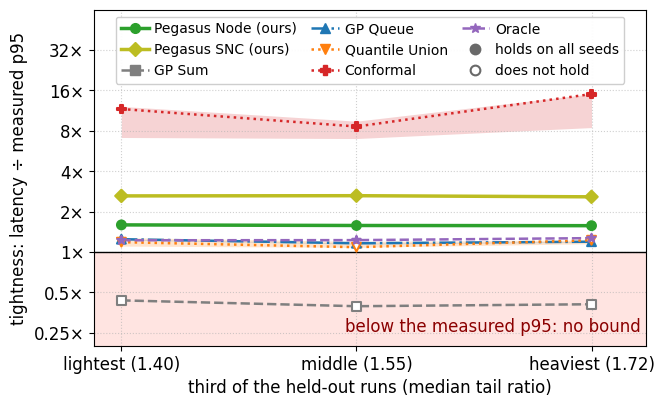

In [3]:
tail_statistics = sweep_statistics(tail_methods, tail_truth, execution_tails, seeds, confidence)   # name -> coverage, tightness, holds, computed
# with real data the three groups are placed at equal distances, because their tail ratios are not spread evenly
tail_positions = execution_tails if data_source == "synthetic" else list(range(len(execution_tails)))
tightness_sweep_figure(tail_positions, tail_statistics, tail_axis,
                       f"B.5 tail of the execution time, {data_source} data: {' → '.join(base.path)},\n{arrivals}, {len(seeds)} seeds", p_label,
                       tick_labels=tail_ticks, log_x=False, name=f"b5_tails_{data_source}")

In [4]:
display(Markdown(
    f"**What this shows** ({data_source} data, {arrivals}, ε = {alpha:g}, {len(seeds)} seeds).\n"
    + sweep_conclusion(execution_tails, tail_statistics, sweep_competitors, tail_label)
    + f"\n- **Finite bounds.** Share of the held-out configurations at which a version of Pegasus gives a finite latency (median over the seeds): "
    + "; ".join(f"{name} " + ", ".join(f"{finite_share(tail_methods, name, tail, seeds):.0%} at {tail_label(tail)}" for tail in execution_tails)
                for name in pegasus_versions)
    + ". Where a version gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded; such a bound "
    f"is not violated, but it says nothing.\n"
    + ground_truth_conclusion(execution_tails, tail_truth, tail_statistics, seeds, tail_label, p_label,
                              ", at the same mean execution times" if data_source == "synthetic" else "")
))

**What this shows** (real data, poisson arrivals at one rate per configuration (1.58 to 65/s), ε = 0.05, 3 seeds).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus Node (ours), Pegasus SNC (ours), GP Queue, Conformal. Methods that do not hold, and where: GP Sum at every setting; Quantile Union at tail ratio 1.55, tail ratio 1.72.
- **Tightness among the methods that hold** (median over the seeds): Pegasus Node (ours) from 1.59× at tail ratio 1.40 to 1.57× at tail ratio 1.72; Pegasus SNC (ours) from 2.62× at tail ratio 1.40 to 2.58× at tail ratio 1.72; GP Queue from 1.25× at tail ratio 1.40 to 1.19× at tail ratio 1.72; Conformal from 11.64× at tail ratio 1.40 to 15.05× at tail ratio 1.72.
- **Finite bounds.** Share of the held-out configurations at which a version of Pegasus gives a finite latency (median over the seeds): Pegasus Node (ours) 100% at tail ratio 1.40, 100% at tail ratio 1.55, 100% at tail ratio 1.72; Pegasus SNC (ours) 100% at tail ratio 1.40, 100% at tail ratio 1.55, 100% at tail ratio 1.72. Where a version gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded; such a bound is not violated, but it says nothing.
- **Ground truth.** The measured p95 of the end-to-end latency, the median over the held-out configurations, goes from 0.24 s at tail ratio 1.40 to 0.11 s at tail ratio 1.72. The Oracle, the union bound over measured services, is at 1.22× and 1.27×.

### B.6 Varying Percentiles

- **Synthetic:** every percentile that the simulated runs are long enough to measure.
- **Real:** the same, on the measured held-out runs of B.1; a run measured a few hundred to a few thousand requests,
  so the highest percentiles rest on few requests per run.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal train one model per percentile; the other
  methods use the same execution-time models at every percentile.

**Setting.** For every seed, the chain, the training configurations, the per-service models, the held-out
configurations, the Poisson arrivals and the simulated or measured runs of B.1. Only the percentile that a method has to bound
changes: the *level* is the share of items whose end-to-end latency must lie under the bound, one value of
`percentile_levels` per setting, written as a percentile (level 0.95 is p95, the percentile of B.1). The violation
probability is $\varepsilon$ = 1 − level, so a higher percentile is a smaller $\varepsilon$. The ground truth is the
measured quantile of the end-to-end latency at that level, with the confidence interval of B.1. The highest level is
limited by the length of the simulated runs: a quantile further in the tail would rest on too few items per run to be
measured, in particular the quantile at $1 - \varepsilon / |S|$ that Quantile Union, Conformal and the Oracle read from
the runs of each service.

How the level enters each method: Pegasus Node bounds every service at $\varepsilon / |S|$ and Pegasus SNC the whole
chain at $\varepsilon$, both with the same execution-time models as in B.1. GP Sum takes the level as the quantile of
its Gaussian sum, and GP Queue as the quantile of its waiting-time formula. Quantile Union and Conformal are trained
anew for every level, on the $(1 - \varepsilon / |S|)$ latency quantile of each service monitored alone.

**Figure.** The horizontal axis is the bounded percentile, at equal distances from the lowest to the highest; the
vertical axis is the tightness, the latency of a method ÷ the measured quantile at that percentile, for every seed the
median over its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. In the red area below 1× a method is under the measured quantile and is no bound; the legend sits inside the panel where it hides the fewest points. Every line
is the median over the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker
means that the method holds at that percentile (it reaches the confidence level under every seed, as defined in B.1), a
hollow marker that it does not. Look at the markers first, then at whether a filled line comes closer to 1× or moves
away from it toward the higher percentiles. The figure is also saved as
`figures/tsc/b6_percentiles_<data source>.pdf` and `.jpg`.

In [5]:
# B.6: the chains of B.1 with a different percentile of the end-to-end latency to bound
percentile_levels = [0.5, 0.75, 0.9, 0.95, 0.99]   # level of the bounded latency quantile; the violation probability is 1 - level, and B.1 uses 1 - alpha


def compute():
    percentile_methods, percentile_truth = {}, {}   # (level, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
    for level in percentile_levels:
        for s in seeds:
            data = chain_data(s, level=level)
            assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
            # the execution times do not depend on the percentile, so the per-service models of B.1 are the models of every setting
            assert all(np.array_equal(data.y_train[name], bases[s].y_train[name]) for name in data.path), "the training data differs from that of B.1"
            percentile_methods[(level, s)], _ = compare_methods(data, base_models[s], data.x_train, data.monitored_latencies, 1 - level, confidence,
                                                                n_calibration, model_seed=seed + s, leave_out=only_base_case, x_train_load=data.x_train_load)
            percentile_truth[(level, s)] = (data.measured, data.measured_low)
    return dict(percentile_methods=percentile_methods, percentile_truth=percentile_truth)


globals().update(cached("b6_percentiles", data_source, compute, inputs=dict(percentile_levels=percentile_levels)))
print(f"{len(percentile_methods)} combinations of percentile and seed evaluated.")

b6_percentiles: results loaded from statics\evaluation_cache\b6_percentiles_real_eb37b2f92d4e6ca7.joblib
15 combinations of percentile and seed evaluated.


B.6 bounded percentile, real data: detector → transformer → compressor, 99 held-out configurations per seed,
poisson arrivals at one rate per configuration (1.58 to 65/s), 3 seeds


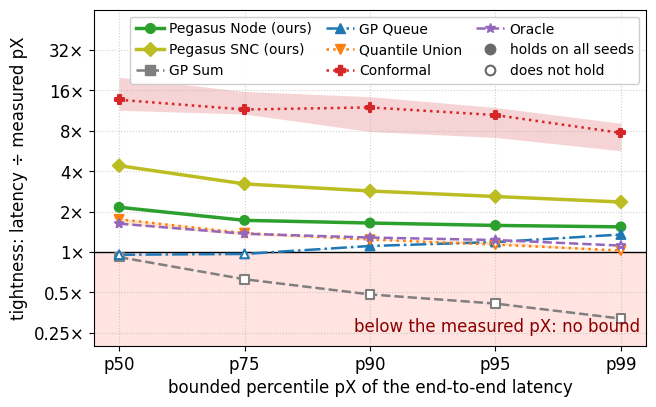

In [6]:
percentile_statistics = sweep_statistics(percentile_methods, percentile_truth, percentile_levels, seeds, confidence)   # name -> coverage, tightness, holds, computed
percentile_label = lambda level: f"p{100 * level:g}"
# the percentiles are placed at equal distances, because neither the level nor the violation probability spreads them evenly
tightness_sweep_figure(list(range(len(percentile_levels))), percentile_statistics, "bounded percentile pX of the end-to-end latency",
                       f"B.6 bounded percentile, {data_source} data: {' → '.join(base.path)}, {len(base.measured)} held-out configurations per seed,\n"
                       f"{arrivals}, {len(seeds)} seeds", "pX",
                       tick_labels=[percentile_label(level) for level in percentile_levels], log_x=False, name=f"b6_percentiles_{data_source}")

In [7]:
display(Markdown(
    f"**What this shows** ({data_source} data, {arrivals}, {len(seeds)} seeds).\n"
    + sweep_conclusion(percentile_levels, percentile_statistics, sweep_competitors, percentile_label) + "\n"
    + ground_truth_conclusion(percentile_levels, percentile_truth, percentile_statistics, seeds, percentile_label, "percentile")
))

**What this shows** (real data, poisson arrivals at one rate per configuration (1.58 to 65/s), 3 seeds).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus Node (ours), Pegasus SNC (ours), Conformal. Methods that do not hold, and where: GP Sum at every setting; GP Queue at p50, p75; Quantile Union at p95, p99.
- **Tightness among the methods that hold** (median over the seeds): Pegasus Node (ours) from 2.15× at p50 to 1.54× at p99; Pegasus SNC (ours) from 4.40× at p50 to 2.36× at p99; Conformal from 13.63× at p50 to 7.72× at p99.
- **Ground truth.** The measured percentile of the end-to-end latency, the median over the held-out configurations, goes from 0.11 s at p50 to 0.30 s at p99. The Oracle, the union bound over measured services, is at 1.63× and 1.12×.